# 05 Main evaluation: Sneaker -> Ankle Boot

**Questions:** To what extent does the fixed Data-to-Data Rectified Flow produce semantically meaningful trajectories & how do those paths compare with direct pixel interpolation?

This notebook evaluates the preselected `medium` best-validation checkpoint on one fixed, reproducibly sampled test cohort. No training or model selection occurs here. Path-based metrics are primary; endpoint target confidence is reported as supplementary because oracle baselines have target information unavailable to RF

In [1]:
from pathlib import Path
import csv
import json
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Markdown, display

cwd = Path.cwd().resolve()
repo_candidates = [cwd, cwd / 'minRF_interpolation']
repo_candidates.extend(
    candidate
    for parent in cwd.parents
    for candidate in (parent, parent / 'minRF_interpolation')
)
repo_candidates.extend((Path('/content/minRF_interpolation'), Path('/content/minrf/minRF_interpolation')))
repo_root = next(
    (candidate for candidate in repo_candidates if (candidate / 'api' / 'flow_model_api.py').is_file()),
    None,
)
if repo_root is None:
    raise FileNotFoundError('Repository not found. Run notebooks/00_colab_setup.ipynb first.')
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from notebooks.utils.colab_paths import find_repository_root

repo_root = find_repository_root(repo_root)
os.chdir(repo_root)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SOURCE_LABEL, TARGET_LABEL = 7, 9
N_PAIRS, EVALUATION_SEED, STEPS = 64, 2026, 50
RESULTS_DIR = repo_root / 'assets' / 'evaluation'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print(f'Device: {device}; test pairs: {N_PAIRS}; integration steps: {STEPS}')

Device: cuda; test pairs: 64; integration steps: 50


In [2]:
from api.evaluation_api import load_eval_classifier
from api.flow_model_api import DatasetSpec, build_dataset_loaders
from notebooks.utils.evaluation_workflow import (
    METHOD_ORDER,
    bootstrap_mean_interval,
    build_reference_banks,
    evaluate_class_pair_cohort,
    load_fixed_flow,
)

PROTOCOL_PATH = RESULTS_DIR / 'evaluation_protocol.json'
EVALUATOR_PATH = RESULTS_DIR / 'fmnist_eval_classifier_v1.pt'
if not PROTOCOL_PATH.is_file() or not EVALUATOR_PATH.is_file():
    raise FileNotFoundError(
        'Run notebooks/04_evaluation_setup.ipynb first to create the evaluator '
        'and frozen evaluation protocol.'
    )
protocol = json.loads(PROTOCOL_PATH.read_text(encoding='utf-8'))
if protocol['flow_pair'] != {'source': SOURCE_LABEL, 'target': TARGET_LABEL}:
    raise ValueError('Notebook pair does not match the frozen protocol')
if (protocol['evaluation_pairs'], protocol['evaluation_seed'], protocol['trajectory_steps']) != (N_PAIRS, EVALUATION_SEED, STEPS):
    raise ValueError('Notebook evaluation settings do not match the frozen protocol')

checkpoint_path = repo_root / protocol['flow_checkpoint']
flow_model, checkpoint_metadata, checkpoint_config = load_fixed_flow(
    checkpoint_path,
    device,
    expected_source=SOURCE_LABEL,
    expected_target=TARGET_LABEL,
    expected_profile='medium',
)
evaluator = load_eval_classifier(EVALUATOR_PATH, device)

dataset_spec = DatasetSpec(
    root=str(repo_root / 'data'),
    source_class=SOURCE_LABEL,
    target_class=TARGET_LABEL,
    seed=42,
)
data = build_dataset_loaders(dataset_spec, download=True)
reference_banks = build_reference_banks(
    data['train_dataset'],
    data['train_label_index'],
    (SOURCE_LABEL, TARGET_LABEL),
)
print('Loaded the fixed checkpoint and frozen evaluator.')
print(f"Embedded checkpoint epoch: {checkpoint_metadata['epochs_completed']}")
print(f"Best validation loss: {checkpoint_metadata['best_validation_loss']:.6f}")

Loaded the fixed checkpoint and frozen evaluator.
Embedded checkpoint epoch: 44
Best validation loss: 0.043487


In [3]:
cohort = evaluate_class_pair_cohort(
    flow_model=flow_model,
    eval_model=evaluator,
    test_dataset=data['test_dataset'],
    test_label_index=data['test_label_index'],
    reference_banks=reference_banks,
    source_label=SOURCE_LABEL,
    target_label=TARGET_LABEL,
    n_pairs=N_PAIRS,
    steps=STEPS,
    seed=EVALUATION_SEED,
    device=device,
)
methods = cohort['methods']
print('Evaluated methods:', ', '.join(METHOD_ORDER))
print('First fixed test pair:', cohort['pair_indices'][0])

Evaluated methods: rectified_flow, identity, global_shift, linear_oracle, nn_linear_oracle
First fixed test pair: {'source_index': 1301, 'target_index': 6741}


In [ ]:
from pathlib import Path
import json

REVIEW_SEED = protocol['human_review']['seed']
N_REVIEW_PAIRS = protocol['human_review']['pairs']
REVIEW_TIME_INDICES = np.arange(STEPS + 1)
if len(REVIEW_TIME_INDICES) != protocol['human_review']['animation_frames']:
    raise ValueError('Human-review animation frame count does not match the frozen protocol')
review_rng = np.random.default_rng(REVIEW_SEED)
review_pair_positions = np.sort(review_rng.choice(
    len(cohort['pair_indices']),
    size=min(N_REVIEW_PAIRS, len(cohort['pair_indices'])),
    replace=False,
))
review_dir = RESULTS_DIR / 'human_review'
review_dir.mkdir(parents=True, exist_ok=True)
image_shape = cohort['trajectories'][METHOD_ORDER[0]][0][0].shape
review_trajectories = np.empty(
    (len(review_pair_positions), len(METHOD_ORDER), len(REVIEW_TIME_INDICES), *image_shape),
    dtype=np.float32,
)
review_key = {
    'seed': REVIEW_SEED,
    'time_indices': REVIEW_TIME_INDICES.tolist(),
    'timepoints': protocol['human_review']['timepoints'],
    'tasks': {},
}
for review_index, pair_position in enumerate(review_pair_positions):
    randomized_methods = review_rng.permutation(METHOD_ORDER).tolist()
    pair_id = f'pair_{review_index:03d}'
    review_key['tasks'][pair_id] = {
        chr(ord('A') + code_index): method
        for code_index, method in enumerate(randomized_methods)
    }
    for code_index, method in enumerate(randomized_methods):
        trajectory = cohort['trajectories'][method]
        review_trajectories[review_index, code_index] = np.stack([
            trajectory[time_index][pair_position].detach().cpu().numpy()
            for time_index in REVIEW_TIME_INDICES
        ])

npz_path = review_dir / 'blinded_review_trajectories.npz'
key_path = review_dir / 'blinded_review_key.json'
np.savez_compressed(
    npz_path,
    trajectories=review_trajectories,
    pair_positions=review_pair_positions,
    time_indices=REVIEW_TIME_INDICES,
)
key_path.write_text(json.dumps(review_key, indent=2) + '\n', encoding='utf-8')
print(f'Blinded review trajectories saved: {npz_path}')
print(f'Keep the method key private until ratings are complete: {key_path}')

## Qualitative plausibility and trajectory inspection

The display uses the **first pair selected by the fixed seed**, not a pair chosen after looking at outcomes. Inspect plausibility, gradual appearance of target-related features, unintended changes, and abrupt transitions. This is one illustrative pair only; quantitative results below use all 64 pairs.

The display clips pixel values to [-1, 1] for visualization only; metrics are calculated on the original, unclipped trajectory.

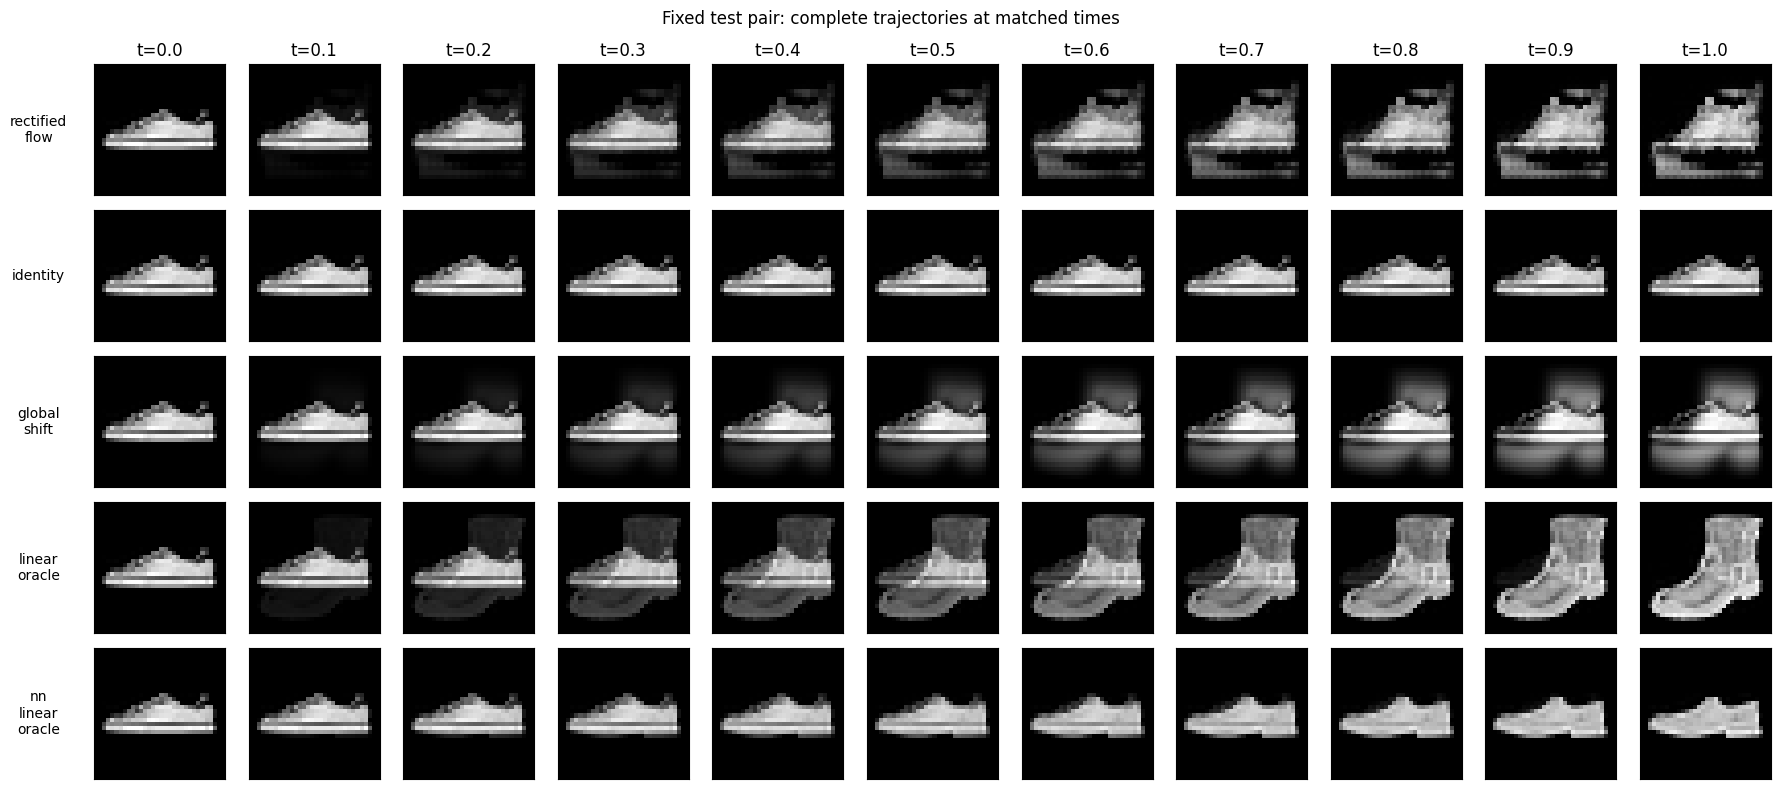

In [4]:
display_steps = np.linspace(0, STEPS, 11, dtype=int)
fig, axes = plt.subplots(len(METHOD_ORDER), len(display_steps), figsize=(18, 8))
for row, method in enumerate(METHOD_ORDER):
    trajectory = cohort['trajectories'][method]
    for column, step in enumerate(display_steps):
        image = trajectory[step][0, 0].detach().cpu().clamp(-1, 1).add(1).div(2)
        axes[row, column].imshow(image, cmap='gray', vmin=0, vmax=1)
        axes[row, column].set_xticks([])
        axes[row, column].set_yticks([])
        if row == 0:
            axes[row, column].set_title(f't={step / STEPS:.1f}')
    axes[row, 0].set_ylabel(method.replace('_', '\n'), rotation=0, labelpad=40, va='center')
fig.suptitle('Fixed test pair: complete trajectories at matched times')
fig.tight_layout()
trajectory_figure = RESULTS_DIR / 'main_trajectory_comparison.png'
fig.savefig(trajectory_figure, dpi=160, bbox_inches='tight')
plt.show()

## Path metrics and uncertainty

Bands below are pointwise paired-test-cohort bootstrap 95% intervals for mean curve (not simultaneous trajectory-wide intervals). 
Monotonicity means every target-confidence increment is at least −0.01. 
Classifier scores are proxies, not direct attribute measures or distributional plausibility guarantees.

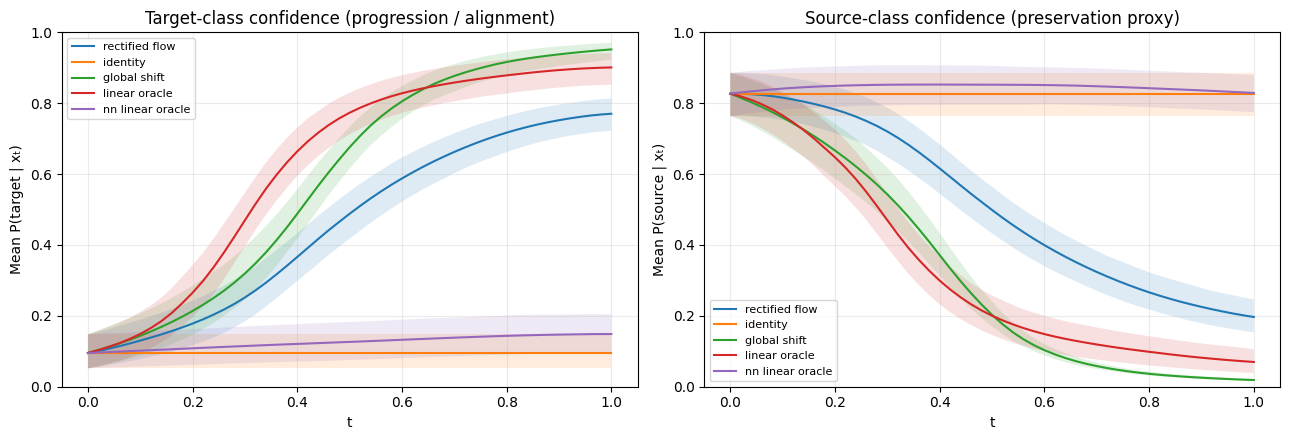

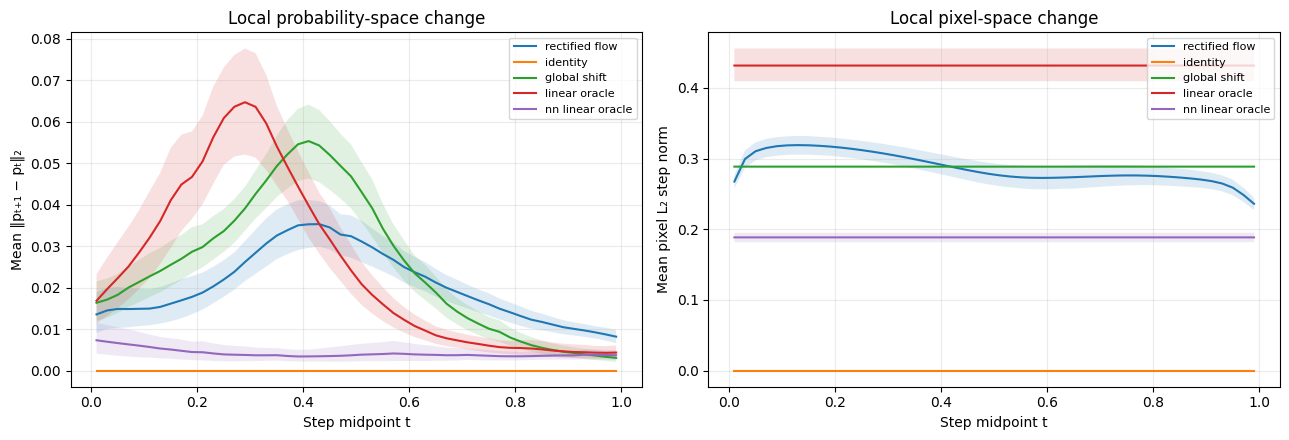

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
time = np.linspace(0, 1, STEPS + 1)
for method in METHOD_ORDER:
    samples = methods[method]['metrics']['sample_metrics']
    target_curves = np.asarray([sample['target_confidence'] for sample in samples])
    mean, lower, upper = bootstrap_mean_interval(target_curves, seed=EVALUATION_SEED)
    axes[0].plot(time, mean, label=method.replace('_', ' '))
    axes[0].fill_between(time, lower, upper, alpha=0.14)

    source_curves = np.asarray([sample['source_confidence'] for sample in samples])
    source_mean, source_lower, source_upper = bootstrap_mean_interval(
        source_curves, seed=EVALUATION_SEED + 1
    )
    axes[1].plot(time, source_mean, label=method.replace('_', ' '))
    axes[1].fill_between(time, source_lower, source_upper, alpha=0.14)

axes[0].set(title='Target-class confidence (progression / alignment)', xlabel='t', ylabel='Mean P(target | xₜ)', ylim=(0, 1))
axes[1].set(title='Source-class confidence (preservation proxy)', xlabel='t', ylabel='Mean P(source | xₜ)', ylim=(0, 1))
for axis in axes:
    axis.grid(alpha=0.25)
    axis.legend(fontsize=8)
fig.tight_layout()
curve_figure = RESULTS_DIR / 'main_semantic_curves.png'
fig.savefig(curve_figure, dpi=160, bbox_inches='tight')
plt.show()

step_time = (np.arange(STEPS) + 0.5) / STEPS
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for method in METHOD_ORDER:
    result = methods[method]
    samples = result['metrics']['sample_metrics']
    probability_steps = np.asarray([sample['prob_gradient'] for sample in samples])
    mean, lower, upper = bootstrap_mean_interval(
        probability_steps, seed=EVALUATION_SEED + 2
    )
    axes[0].plot(step_time, mean, label=method.replace('_', ' '))
    axes[0].fill_between(step_time, lower, upper, alpha=0.14)

    pixel_steps = np.asarray(result['pixel_smoothness']['per_sample_step_sizes']).T
    mean, lower, upper = bootstrap_mean_interval(
        pixel_steps, seed=EVALUATION_SEED + 3
    )
    axes[1].plot(step_time, mean, label=method.replace('_', ' '))
    axes[1].fill_between(step_time, lower, upper, alpha=0.14)

axes[0].set(title='Local probability-space change', xlabel='Step midpoint t', ylabel='Mean ‖pₜ₊₁ − pₜ‖₂')
axes[1].set(title='Local pixel-space change', xlabel='Step midpoint t', ylabel='Mean pixel L₂ step norm')
for axis in axes:
    axis.grid(alpha=0.25)
    axis.legend(fontsize=8)
fig.tight_layout()
smoothness_figure = RESULTS_DIR / 'main_smoothness_curves.png'
fig.savefig(smoothness_figure, dpi=160, bbox_inches='tight')
plt.show()

## Feature-space criteria: alignment, preservation, plausibility proxy, and smoothness

The frozen evaluator's L2-normalized penultimate features are compared with source/target reference images from the **training split only**. Curves show nearest-target cosine distance (lower is closer to target-class examples), nearest source-or-target reference distance (a limited pair-support proxy), cosine similarity to each sample's own source (individual feature-preservation proxy), and local cosine feature distance (feature-space smoothness). These measures use the classifier's representation and are not independent proof of realism or preservation of specific attributes.

In [ ]:
feature_specs = [
    ('target_reference_distance', 'Nearest target-reference distance', 'Cosine distance'),
    ('pair_reference_distance', 'Nearest source/target reference distance', 'Cosine distance'),
    ('source_feature_similarity', 'Similarity to this sample’s source', 'Cosine similarity'),
    ('feature_step_distance', 'Local feature-space change', 'Cosine distance'),
]
feature_time = np.linspace(0, 1, STEPS + 1)
step_time = (np.arange(STEPS) + 0.5) / STEPS
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for axis, (metric, title, ylabel) in zip(axes.flat, feature_specs):
    curve_time = step_time if metric == 'feature_step_distance' else feature_time
    for method in METHOD_ORDER:
        samples = methods[method]['feature_metrics']['sample_metrics']
        values = np.asarray([sample[metric] for sample in samples])
        mean, lower, upper = bootstrap_mean_interval(values, seed=EVALUATION_SEED + 30)
        axis.plot(curve_time, mean, label=method.replace('_', ' '))
        axis.fill_between(curve_time, lower, upper, alpha=0.12)
    axis.set(title=title, xlabel='t', ylabel=ylabel)
    axis.grid(alpha=0.25)
    axis.legend(fontsize=7)
fig.tight_layout()
feature_figure = RESULTS_DIR / 'main_feature_space_metrics.png'
fig.savefig(feature_figure, dpi=160, bbox_inches='tight')
plt.show()

In [ ]:
def interval_text(values, seed):
    mean, lower, upper = bootstrap_mean_interval(values, seed=seed)
    return f'{mean:.3f} [{lower:.3f}, {upper:.3f}]'

summary_rows = []
for method in METHOD_ORDER:
    result = methods[method]
    samples = result['metrics']['sample_metrics']
    pixel_steps = np.asarray(result['pixel_smoothness']['per_sample_step_sizes']).T
    feature_samples = result['feature_metrics']['sample_metrics']
    summary_rows.append({
        'method': method,
        'target Δ (end-start)': interval_text(
            [s['target_confidence'][-1] - s['target_confidence'][0] for s in samples], EVALUATION_SEED
        ),
        'monotonic paths (%)': interval_text(
            [100 * float(s['target_confidence_monotonic']) for s in samples], EVALUATION_SEED + 1
        ),
        'source confidence drop': interval_text(
            [s['source_confidence_drop'] for s in samples], EVALUATION_SEED + 2
        ),
        'classifier confidence proxy': interval_text(
            [np.mean(s['max_class_confidence']) for s in samples], EVALUATION_SEED + 3
        ),
        'probability step change': interval_text(
            [np.mean(s['prob_gradient']) for s in samples], EVALUATION_SEED + 4
        ),
        'pixel step norm': interval_text(
            pixel_steps.mean(axis=1), EVALUATION_SEED + 5
        ),
        'endpoint target confidence*': interval_text(
            [s['endpoint_target_confidence'] for s in samples], EVALUATION_SEED + 6
        ),
        'target-feature distance Δ': interval_text(
            [s['target_reference_distance'][-1] - s['target_reference_distance'][0] for s in feature_samples], EVALUATION_SEED + 7
        ),
        'source-feature similarity (end)': interval_text(
            [s['source_feature_similarity'][-1] for s in feature_samples], EVALUATION_SEED + 8
        ),
        'pair-support distance (mean)': interval_text(
            [np.mean(s['pair_reference_distance']) for s in feature_samples], EVALUATION_SEED + 9
        ),
        'feature step distance (mean)': interval_text(
            [np.mean(s['feature_step_distance']) for s in feature_samples], EVALUATION_SEED + 10
        ),
    })

table = '| Method | Target Δ (end-start) | Monotonic paths (%) | Source confidence drop | Classifier confidence proxy | Probability step change | Pixel step norm | Endpoint target confidence* | Target-feature distance Δ | Source-feature similarity (end) | Pair-support distance (mean) | Feature step distance (mean) |\n'
table += '|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|\n'
for row in summary_rows:
    table += '| ' + ' | '.join(str(value) for value in row.values()) + ' |\n'
display(Markdown(table + '\n*Supplementary endpoint measure; target-informed references have an oracle advantage. Values show mean [bootstrap 95% interval].'))

csv_path = RESULTS_DIR / 'main_evaluation_summary.csv'
with csv_path.open('w', newline='', encoding='utf-8') as handle:
    writer = csv.DictWriter(handle, fieldnames=summary_rows[0].keys())
    writer.writeheader()
    writer.writerows(summary_rows)

output = {
    'protocol': protocol,
    'checkpoint_metadata': checkpoint_metadata,
    'checkpoint_config': checkpoint_config,
    'evaluator_config': torch.load(EVALUATOR_PATH, map_location='cpu').get('config'),
    'cohort': {
        'config': cohort['config'],
        'pair_indices': cohort['pair_indices'],
        'methods': methods,
    },
    'summary': summary_rows,
'figures': [str(trajectory_figure), str(curve_figure), str(smoothness_figure), str(feature_figure)],
}
result_path = RESULTS_DIR / 'main_evaluation_results.json'
result_path.write_text(json.dumps(output, indent=2) + '\n', encoding='utf-8')
print(f'Saved raw per-sample metrics: {result_path}')
print(f'Saved table: {csv_path}')

In [ ]:
rf_samples = methods['rectified_flow']['metrics']['sample_metrics']
paired_rows = []
fig, axis = plt.subplots(figsize=(8, 4.5))
rf_target_curves = np.asarray([sample['target_confidence'] for sample in rf_samples])
for method in METHOD_ORDER[1:]:
    samples = methods[method]['metrics']['sample_metrics']
    target_curves = np.asarray([sample['target_confidence'] for sample in samples])
    differences = target_curves - rf_target_curves
    mean, lower, upper = bootstrap_mean_interval(
        differences, seed=EVALUATION_SEED + METHOD_ORDER.index(method)
    )
    axis.plot(time, mean, label=method.replace('_', ' '))
    axis.fill_between(time, lower, upper, alpha=0.16)

    rf_progress = rf_target_curves[:, -1] - rf_target_curves[:, 0]
    method_progress = target_curves[:, -1] - target_curves[:, 0]
    rf_monotonic = np.asarray([
        sample['target_confidence_monotonic'] for sample in rf_samples
    ], dtype=float)
    method_monotonic = np.asarray([
        sample['target_confidence_monotonic'] for sample in samples
    ], dtype=float)
    rf_feature_samples = methods['rectified_flow']['feature_metrics']['sample_metrics']
    method_feature_samples = methods[method]['feature_metrics']['sample_metrics']
    paired_rows.append({
        'baseline': method,
        'paired target progression difference vs RF': interval_text(
            method_progress - rf_progress, EVALUATION_SEED + 20
        ),
        'paired monotonic-path difference vs RF (pp)': interval_text(
            100 * (method_monotonic - rf_monotonic), EVALUATION_SEED + 21
        ),
        'paired target-feature distance Δ vs RF': interval_text(
            np.asarray([s['target_reference_distance'][-1] - s['target_reference_distance'][0] for s in method_feature_samples])
            - np.asarray([s['target_reference_distance'][-1] - s['target_reference_distance'][0] for s in rf_feature_samples]),
            EVALUATION_SEED + 22,
        ),
        'paired source-feature similarity at end vs RF': interval_text(
            np.asarray([s['source_feature_similarity'][-1] for s in method_feature_samples])
            - np.asarray([s['source_feature_similarity'][-1] for s in rf_feature_samples]),
            EVALUATION_SEED + 23,
        ),
    })

axis.axhline(0, color='black', linewidth=1, alpha=0.7)
axis.set(
    title='Paired target-confidence curve difference (baseline − RF)',
    xlabel='t',
    ylabel='Difference in P(target | xₜ)',
)
axis.grid(alpha=0.25)
axis.legend(fontsize=8)
fig.tight_layout()
paired_figure = RESULTS_DIR / 'main_paired_target_differences.png'
fig.savefig(paired_figure, dpi=160, bbox_inches='tight')
plt.show()

paired_table = '| Baseline | Paired target progression difference vs RF | Paired monotonic-path difference vs RF (pp) | Paired target-feature distance Δ vs RF | Paired source-feature similarity at end vs RF |\n|---|---:|---:|---:|---:|\n'
for row in paired_rows:
    paired_table += f"| {row['baseline']} | {row['paired target progression difference vs RF']} | {row['paired monotonic-path difference vs RF (pp)']} | {row['paired target-feature distance Δ vs RF']} | {row['paired source-feature similarity at end vs RF']} |\n"
display(Markdown(paired_table + '\nPositive values favor the baseline; negative values favor RF. Intervals are pointwise paired-test-cohort bootstrap 95% intervals.'))
paired_csv = RESULTS_DIR / 'main_paired_differences.csv'
with paired_csv.open('w', newline='', encoding='utf-8') as handle:
    writer = csv.DictWriter(handle, fieldnames=paired_rows[0].keys())
    writer.writeheader()
    writer.writerows(paired_rows)
output['paired_comparisons'] = paired_rows
output['figures'].append(str(paired_figure))
result_path.write_text(json.dumps(output, indent=2) + '\n', encoding='utf-8')
print(f'Saved paired comparisons: {paired_csv}')

## Interpretation checklist

- **RQ1:** Which criteria are represented quantitatively, and which remain qualitative? Do not treat any single score as semantic meaningfulness.
- **RQ2:** Does target confidence rise progressively for the fixed RF? Are there abrupt probability/pixel changes? Do intermediate images remain plausible on inspection?
- **RQ3:** How does RF compare with non-oracle baselines along the path? How does it compare with the oracle references, while keeping their target-information advantage explicit?

- **Plausibility:** Combine the single-pair visual example, maximum classifier confidence, and nearest source/target training-reference feature distance. These are proxies, not calibrated realism judgments; Notebook 07 adds blinded human ratings.
- **Semantic progression:** Does target confidence increase along the fixed RF path? Report the path curve and per-example monotonicity; neither guarantees visible attribute change.
- **Target alignment:** Compare target-class probability with nearest-target training-reference feature distance. Lower feature distance indicates representation-space proximity, not a paired target match.
- **Preservation:** Source-class confidence and similarity to each sample's own initial evaluator embedding are indirect proxies; neither isolates non-target attributes.
- **Smoothness:** Inspect probability, pixel, and feature-space step curves. A smaller step is not automatically better if semantic progress is also small.
- **Baseline comparison:** Report paired differences and intervals; separate non-oracle baselines from target-informed references.
- **Scope:** Conclusions apply to this checkpoint, class pair, evaluator, and sampled cohort. Notebook 06 varies test cohorts; Notebook 07 reports a human-review pilot.